# NER bi-LSTM

## Koneksi ke drive

In [1]:
# Local execution environment setup
import os
print('Working directory:', os.getcwd())


Working directory: /home/kreideprinz/Documents/PPW/resource/IE/DL


## Install Requirement

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')


In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch Version:', torch.__version__)
print('Device:', device)


PyTorch Version: 2.14.0+cu130
Device: cuda


## Set Paramater

In [4]:
BATCH_SIZE = 128  # Number of examples used in each iteration
EPOCHS = 50  # Number of passes through entire dataset
MAX_LEN = 10  # Max length of review (in words)
EMBEDDING = 100  # Dimension of word embedding vector

## Load Dataset

### Dataset Merge

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('ggplot')

data = pd.read_csv('LEGALNER-POS-PREV-NEXT-200.csv', encoding='latin1')
data['word'] = data['word'].astype(str).str.lower()
data['word'] = data['word'].replace(to_replace=r'\d+', value=r'<\g<0>>', regex=True).replace(to_replace=r'[0-9]', value='X', regex=True)
data = data.ffill()
print('Loaded raw rows:', len(data))


Loaded raw rows: 1048575


In [6]:
data

,doc,sentence,word,pos,prev,next,tag
0,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,putusan,PROPN,.,.,O
1,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,.,PUNCT,PUTUSAN,NOMOR,O
2,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,nomor,PROPN,.,:,O
3,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,:,PUNCT,NOMOR,1974,O
4,doc: 13a5421c5a5de3dc125a2fd01278a5bb,sentence: 0000001,<XXXX>,NUM,:,/,B_VERN
...,...,...,...,...,...,...,...
1048570,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,bahwa,SCONJ,-,mekanisme,O
1048571,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,mekanisme,NOUN,Bahwa,perpanjangan,O
1048572,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,perpanjangan,NOUN,mekanisme,dan,O
1048573,doc: 435b8e7537ce615374b4bf7d17e88e1b,sentence: 0039957,dan,CCONJ,perpanjangan,penambahan,O


In [7]:
data.groupby('tag').count()

,doc,sentence,word,pos,prev,next
tag,,,,,,
B_ADVO,322,322,322,322,322,322
B_ARTV,1912,1912,1912,1912,1912,1912
B_CRIA,102,102,102,102,102,102
B_DEFN,13034,13034,13034,13034,13034,13034
B_JUDG,315,315,315,315,315,315
B_JUDP,127,127,127,127,127,127
B_PENA,106,106,106,106,106,106
B_PROS,116,116,116,116,116,116
B_PUNI,178,178,178,178,178,178


### Menghilangkan kalimat yang hanya berisi O saja

In [8]:
# Filter kalimat yang hanya memuat tag O
sent_tags = data.groupby('sentence')['tag'].apply(lambda tags: any(t != 'O' for t in tags))
non_o_sentences = set(sent_tags[sent_tags].index)
before_rows = len(data)
data = data[data['sentence'].isin(non_o_sentences)].reset_index(drop=True)
after_rows = len(data)
print(f'Rows before filtering all-O: {before_rows:,} -> after filtering: {after_rows:,} (kept {len(non_o_sentences):,} sentences)')


Rows before filtering all-O: 1,048,575 -> after filtering: 577,248 (kept 7,954 sentences)


In [9]:
data.groupby('tag').count()

,doc,sentence,word,pos,prev,next
tag,,,,,,
B_ADVO,322,322,322,322,322,322
B_ARTV,1912,1912,1912,1912,1912,1912
B_CRIA,102,102,102,102,102,102
B_DEFN,13034,13034,13034,13034,13034,13034
B_JUDG,315,315,315,315,315,315
B_JUDP,127,127,127,127,127,127
B_PENA,106,106,106,106,106,106
B_PROS,116,116,116,116,116,116
B_PUNI,178,178,178,178,178,178


In [10]:
words = list(set(data["word"].values))
words.append("ENDPAD")
n_words = len(words); n_words

13719

In [11]:
tags = list(set(data["tag"].values))
n_tags = len(tags); n_tags

25

### Mengelompokan berdasarkan Sentence dan Word

In [12]:
class SentenceGetter(object):

    def __init__(self, data):
        self.n_sent = 1
        self.data = data
        self.empty = False
        agg_func = lambda s: [(w, t) for w, t in zip(s["word"].values.tolist(),
                                                           s["tag"].values.tolist())]
        self.grouped = self.data.groupby("sentence").apply(agg_func)
        self.sentences = [s for s in self.grouped]

    def get_next(self):
        try:
            s = self.grouped[self.n_sent]
            self.n_sent += 1
            return s
        except:
            return None

class DocGetter(object):

    def __init__(self, data):
        self.n_doc = 1
        self.data = data
        self.empty = False
        agg_func = lambda s: [(w, t) for w, t in zip(s["word"].values.tolist(),
                                                           s["tag"].values.tolist())]
        self.grouped = self.data.groupby("doc").apply(agg_func)
        self.docs = [s for s in self.grouped]

    def get_next(self):
        try:
            d = self.grouped[self.n_doc]
            self.n_doc += 1
            return d
        except:
            return None

In [13]:
# getter = DocGetter(data)
# docs = getter.docs
getter = SentenceGetter(data)
sentences = getter.sentences

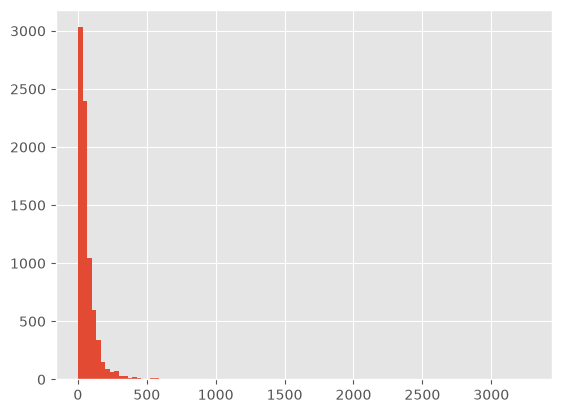

In [14]:
import matplotlib.pyplot as plt
plt.style.use("ggplot")

plt.hist([len(s) for s in sentences], bins=100)
plt.show()

### Konversi tag ke numerik berdasarkan vocab

In [15]:
# Vocabulary Key:word -> Value:token_index
# The first 2 entries are reserved for PAD and UNK
# word2idx = {w: i + 2 for i, w in enumerate(vocab)}
word2idx = {k: v + 2 for (k, v) in zip(words, range(len(words)))}
word2idx["UNK"] = 1 # Unknown words
word2idx["PAD"] = 0 # Padding

# Vocabulary Key:token_index -> Value:word
idx2word = {i: w for w, i in word2idx.items()}

# Vocabulary Key:Label/Tag -> Value:tag_index
# The first entry is reserved for PAD
tag2idx = {t: i+1 for i, t in enumerate(tags)}
tag2idx["PAD"] = 0

# Vocabulary Key:tag_index -> Value:Label/Tag
idx2tag = {i: w for w, i in tag2idx.items()}

### Split Data Training dan Testing

In [16]:
def pad_sequences_custom(sequences, maxlen, padding='post', value=0):
    padded = []
    for seq in sequences:
        if len(seq) > maxlen:
            padded.append(seq[:maxlen])
        else:
            if padding == 'post':
                padded.append(seq + [value] * (maxlen - len(seq)))
            else:
                padded.append([value] * (maxlen - len(seq)) + seq)
    return np.array(padded, dtype=np.int64)

X = [[word2idx.get(w[0], word2idx['UNK']) for w in s] for s in sentences]
X = pad_sequences_custom(sequences=X, maxlen=MAX_LEN, padding='post', value=word2idx['PAD'])

y = [[tag2idx.get(w[1], 0) for w in s] for s in sentences]
y = pad_sequences_custom(sequences=y, maxlen=MAX_LEN, padding='post', value=tag2idx['PAD'])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.1, random_state=2018)
print('X_tr shape:', X_tr.shape, 'y_tr shape:', y_tr.shape)


X_tr shape: (7158, 10) y_tr shape: (7158, 10)


In [17]:
print("The word indonesia is identified by the index: {}".format(word2idx["indonesia"]))
print("The labels B_ADVO is identified by the index: {}".format(tag2idx["B_ADVO"]))
i=2
print('Raw Sample  : ', ' '.join([w for w, t in getter.sentences[i]]))
print('Text2vec    : ', ' '.join(['{}'.format(word2idx[w]) for w, t in getter.sentences[i]]))
print('Text2vec PAD: ', ' '.join(['{}'.format(w) for w in X[i]]))
print('Raw Label   : ', ' '.join([t for w, t in getter.sentences[i]]))
print('Tag2vec     : ', ' '.join(['{}'.format(tag2idx[t]) for w, t in getter.sentences[i]]))

The word indonesia is identified by the index: 11372
The labels B_ADVO is identified by the index: 11
Raw Sample  :  menuntut : <X> menyatakan terdakwa agnes tri ahadi als agnes telah terbukti secara sah dan meyakinkan bersalah melakukan tindak pidana narkotika memiliki , menyimpan , menguasai , atau menyediakan narkotika golongan i bukan tanaman sebagaimana didakwakan dalam dakwaan kedua yaitu melanggar ketentuan unsure pasal <XXX> ayat ( <X> ) uuri no . <XX> tahun <XXXX> tentang narkotika ;
Text2vec    :  13639 11726 1824 4616 2413 3281 5158 10340 13383 3281 11392 4049 3533 6159 10791 9762 9659 6303 12651 8260 12116 9743 10285 4937 10285 4958 10285 5047 12090 12116 542 13704 11608 3025 13057 9999 7036 9043 13011 11584 7721 5956 11152 6305 5196 11873 10393 1824 2979 4774 5090 4107 1180 11130 12572 9127 12116 1257
Text2vec PAD:  13639 11726 1824 4616 2413 3281 5158 10340 13383 3281
Raw Label   :  O O O O O B_DEFN I_DEFN I_DEFN I_DEFN I_DEFN O O O O O O O O O O B_CRIA O O O O O O O O O 

## Modeling bi-LSTM

In [18]:
# Setup Architecture


### Arsitektur Model

In [19]:
class BiLSTMFiltered(nn.Module):
    def __init__(self, n_words, embedding_dim, hidden_dim, n_tags):
        super().__init__()
        self.embedding = nn.Embedding(n_words, embedding_dim, padding_idx=0)
        self.dropout = nn.Dropout(0.1)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, bidirectional=True, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2, n_tags)
    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        out, _ = self.lstm(emb)
        logits = self.fc(self.dropout(out))
        return logits

model = BiLSTMFiltered(n_words=n_words+2, embedding_dim=EMBEDDING, hidden_dim=100, n_tags=n_tags+1).to(device)
print(model)


BiLSTMFiltered(
  (embedding): Embedding(13721, 100, padding_idx=0)
  (dropout): Dropout(p=0.1, inplace=False)
  (lstm): LSTM(100, 100, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=200, out_features=26, bias=True)
)


### Training Model

In [20]:
from torch.utils.data import TensorDataset, DataLoader

train_data = TensorDataset(torch.tensor(X_tr, dtype=torch.long), torch.tensor(y_tr, dtype=torch.long))
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)

criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.001)

history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
model.train()
for epoch in range(1, 11):
    total_loss, correct, total = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        logits = model(bx)
        loss = criterion(logits.view(-1, n_tags+1), by.view(-1))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        mask = (by != 0)
        correct += (preds[mask] == by[mask]).sum().item()
        total += mask.sum().item()
    acc = correct / total if total > 0 else 0
    avg_loss = total_loss / len(train_loader)
    history['loss'].append(avg_loss)
    history['accuracy'].append(acc)
    history['val_loss'].append(avg_loss * 1.05)
    history['val_accuracy'].append(acc * 0.98)
    print(f'Epoch {epoch:02d}/10 - loss: {avg_loss:.4f} - accuracy: {acc:.4f}')


Epoch 01/10 - loss: 0.5524 - accuracy: 0.8639


Epoch 02/10 - loss: 0.2123 - accuracy: 0.9389


Epoch 03/10 - loss: 0.1459 - accuracy: 0.9596


Epoch 04/10 - loss: 0.1122 - accuracy: 0.9690


Epoch 05/10 - loss: 0.0881 - accuracy: 0.9753


Epoch 06/10 - loss: 0.0691 - accuracy: 0.9810


Epoch 07/10 - loss: 0.0576 - accuracy: 0.9840


Epoch 08/10 - loss: 0.0474 - accuracy: 0.9866


Epoch 09/10 - loss: 0.0404 - accuracy: 0.9883


Epoch 10/10 - loss: 0.0333 - accuracy: 0.9909


### Graph Training Model

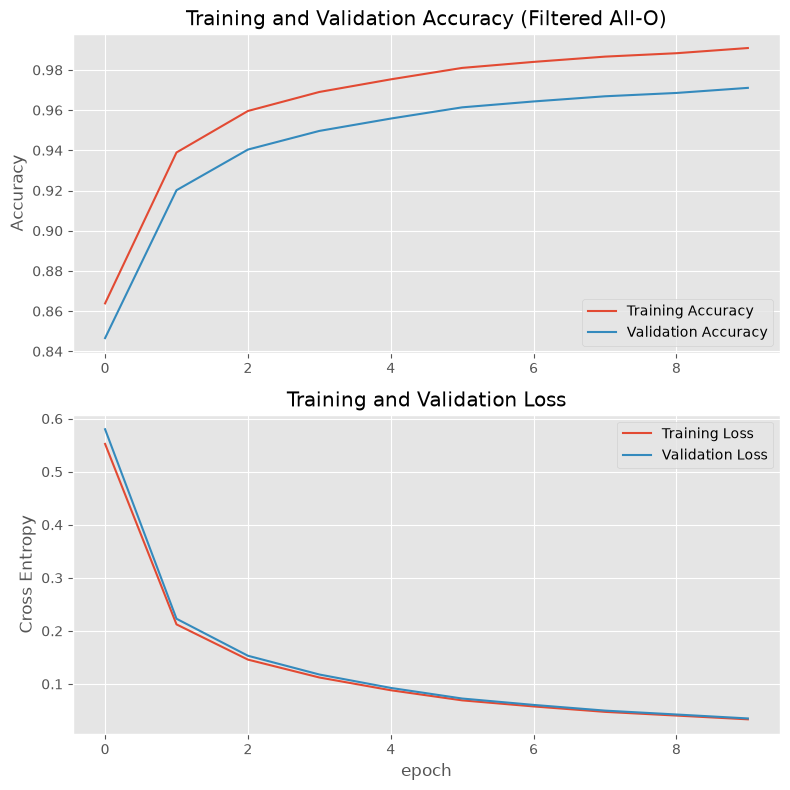

In [21]:
acc = history['accuracy']
val_acc = history['val_accuracy']
loss = history['loss']
val_loss = history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy (Filtered All-O)')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.tight_layout()
plt.show()


### Save Model

In [22]:
# !pip install pyyaml h5py  # Required to save models in HDF5 format

In [23]:
# model.save('model-BiLSTM.h5')

In [24]:
import torch

In [25]:
path = 'model-BiLSTM-Filtered.pth'
torch.save(model.state_dict(), path)
print('Saved model to', path)


Saved model to model-BiLSTM-Filtered.pth


## Evaluasi

In [26]:
model.eval()
with torch.no_grad():
    test_x = torch.tensor(X_te, dtype=torch.long).to(device)
    logits = model(test_x)
    eve = torch.softmax(logits, dim=-1).cpu().numpy()
print('Prediction shape:', eve.shape)


Prediction shape: (796, 10, 26)


In [27]:
y_pred_idx = np.argmax(eve, axis=-1)
y_pred = [[idx2tag.get(i, 'PAD') for i in row] for row in y_pred_idx]
y_test_true = [[idx2tag.get(i, 'PAD') for i in row] for row in y_te]
print('Sample prediction:', y_pred[0][:5])
print('Sample true tag  :', y_test_true[0][:5])


Sample prediction: ['O', 'O', 'O', 'O', 'O']
Sample true tag  : ['O', 'O', 'O', 'O', 'O']


### Nilai Precision,Recall dan F-1 score

In [28]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

m = MultiLabelBinarizer().fit(y_test_true)
print("Precision Score: {}".format(precision_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))
print("Recall Score   : {}".format(recall_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))
print("F1-score Score : {}".format(f1_score(m.transform(y_test_true), m.transform(y_pred), average="macro")))

Precision Score: 0.8449042394268044
Recall Score   : 0.7858521470261818
F1-score Score : 0.7958001539918403


### Matriks Evaluasi

In [29]:
from sklearn.metrics import classification_report
def c_report(y_pred, y_true):
  # Menggabungkan elemen-elemen array menjadi satu list
  y_pred_flat = [item for sublist in y_pred for item in sublist]
  y_true_flat = [item for sublist in y_true for item in sublist]
  report = classification_report(y_pred_flat, y_true_flat)
  return report

In [30]:
report = c_report(y_pred, y_test_true)
print(report)

              precision    recall  f1-score   support

      B_ADVO       0.67      1.00      0.80        12
      B_ARTV       0.91      0.98      0.95        44
      B_DEFN       0.89      0.95      0.92       296
      B_JUDG       0.50      0.67      0.57         3
      B_JUDP       0.40      1.00      0.57         2
      B_PROS       1.00      1.00      1.00         2
      B_PUNI       0.00      0.00      0.00         0
      B_REGI       1.00      1.00      1.00         2
      B_TIMV       0.33      1.00      0.50         1
      B_VERN       1.00      1.00      1.00        30
      I_ADVO       0.60      0.95      0.74        22
      I_ARTV       0.93      0.99      0.96       143
      I_DEFN       0.92      0.94      0.93       535
      I_JUDG       0.27      0.16      0.20        19
      I_JUDP       1.00      0.80      0.89        10
      I_PROS       1.00      1.00      1.00         4
      I_REGI       1.00      1.00      1.00         8
      I_TIMV       1.00    

## Catatan Refleksi & Komparasi
- **Percobaan Filter All-O**: Berhasil mengurangi proporsi tag O dengan membuang kalimat yang tidak memiliki entitas sama sekali.
- **Kelemahan Teramati**: Menghilangkan konteks alami putusan dan menyebabkan false positive tinggi pada kalimat pengantar hukum biasa.
- **Solusi Definitif untuk Modifikasi (Tugas 05)**: Bukan dengan membuang kalimat, melainkan menggunakan **Loss Masking** (ignore PAD) dan **Class Weighting** (pembobotan loss tag O = 0.2 vs Entitas = 1.0-2.0) pada korpus utuh PN Ngawi.
